# Unsupervised Machine Learning-Based Anomaly Detection in Electricity Purchasing and Estimated Consumption Patterns of Prepaid Smart Meter Customers

**Group: 7** \
Name: Auma Mercy Gabriella \
Regno: 2026/HD05/22744U \
Student Number: 2600722744 

**Dataset: UEDCL prepaid purchase histories**

**Assumptions**
1. Only Successful purchases included.
2. Customer-meter pair identity.
3. Units purchased is determined through dividing Resource amount by tariff rate.
4. Zero-balance before the next purchase, assumed not measured.
5. Same-day purchases are aggregated and interval rates become available only aftrt the next purchase.
6. No recorded purchase is not proof of zero consumption.

In [3]:
%pip install numpy pandas scipy scikit-learn joblib threadpoolctl matplotlib nbformat

Note: you may need to restart the kernel to use updated packages.


In [26]:
from pathlib import Path

# Ensure that WORK is a valid directory path.
WORK = Path(WORK).resolve()

# Create the main research output directory.
WORK.mkdir(parents=True, exist_ok=True)

# Define all required experimental subdirectories.
folders = [
    "edufs_v4",
    "kmedoids_v5",
    "anomaly_v6",
    "evaluation_v7",
    "plots"
]

# Create each subdirectory and confirm its availability.
for folder in folders:
    directory = WORK / folder
    directory.mkdir(parents=True, exist_ok=True)

    print(f"PASS: {directory.name} - Directory created or available")

PASS: edufs_v4 - Directory created or available
PASS: kmedoids_v5 - Directory created or available
PASS: anomaly_v6 - Directory created or available
PASS: evaluation_v7 - Directory created or available
PASS: plots - Directory created or available


In [17]:
import os
from pathlib import Path
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from IPython.display import display

os.environ["OPENBLAS_NUM_THREADS"] = "1"
os.environ["OMP_NUM_THREADS"] = "1"

SOURCE = Path("Order Lis_09181045.xlsx").resolve()
WORK = Path("prepaied_notebook_outputs").resolve()

WORK.mkdir(parents=True, exist_ok=True)

RUN_PIPELINE = True

plt.rcParams.update({
    "figure.dpi": 110,
    "axes.spines.top": False,
    "axes.spines.right": False,
    "font.size": 10
})

def finish_plot(title, xlabel="",ylabel=""):
    plt.title(title)
    plt.xlabel(xlabel)
    plt.ylabel(ylabel)
    plt.tight_layout()
    plt.show()


# 1. Source audit and initial weekly features, Version 1 (V1)

I read Excelsheet without modifying it. I, also estimated purchased kWh, aggregated daily purchases and built complete Monday-Sunday weeks, including weeks without purchases.

In [18]:
if RUN_PIPELINE:
    """Reproducible prepaid customer-week features; stdlib-only streaming XLSX input."""
    import csv, zipfile, xml.etree.ElementTree as ET, re, math, statistics, json
    from collections import defaultdict, Counter
    from datetime import date, timedelta
    from pathlib import Path
    ROOT = WORK
    SRC = SOURCE
    NS = '{http://schemas.openxmlformats.org/spreadsheetml/2006/main}'
    START = date(2026, 1, 5)
    END = date(2026, 8, 30)
    RATE_RE = re.compile('(\\d+(?:\\.\\d+)?)\\s*UGX', re.I)

    def records():
        with zipfile.ZipFile(SRC) as z:
            strings = []
            for _, el in ET.iterparse(z.open('xl/sharedStrings.xml'), events=('end',)):
                if el.tag == NS + 'si':
                    strings.append(''.join((n.text or '' for n in el.iter(NS + 't'))))
                    el.clear()
            headers = None
            for _, el in ET.iterparse(z.open('xl/worksheets/sheet1.xml'), events=('end',)):
                if el.tag != NS + 'row':
                    continue
                cells = {}
                for c in el.findall(NS + 'c'):
                    v = c.find(NS + 'v')
                    col = re.match('[A-Z]+', c.attrib['r']).group()
                    raw = v.text if v is not None else ''
                    cells[col] = strings[int(raw)] if c.get('t') == 's' and raw else raw
                cols = [chr(x) for x in range(65, 88)]
                if headers is None:
                    headers = [cells.get(k, '') for k in cols]
                else:
                    yield dict(zip(headers, [cells.get(k, '') for k in cols]))
                el.clear()

    def median(v):
        return round(statistics.median(v), 6) if v else None

    def number(v):
        try:
            return float(v)
        except (ValueError, TypeError):
            return None
    stats = Counter()
    per_day = defaultdict(lambda: defaultdict(lambda: [0, 0.0, 0.0]))
    for r in records():
        stats['total_rows'] += 1
        if r['Excute Status'] != 'Execution Successful':
            continue
        stats['all_successful'] += 1
        try:
            d = date.fromisoformat(r['Vending Date'][:10])
        except ValueError:
            stats['invalid_dates'] += 1
            continue
        if not START <= d <= END:
            continue
        stats['successful_in_window'] += 1
        m = RATE_RE.findall(r['Tariff Program'])
        amt = number(r['Resource Amount(UGX)'])
        if len(m) != 1 or amt is None or float(m[0]) <= 0 or (amt < 0):
            stats['invalid_tariff_or_amount'] += 1
            continue
        k = (r['Customer No.'].strip(), r['Meter No.'].strip())
        if not all(k):
            stats['missing_customer_meter'] += 1
            continue
        v = per_day[k][d]
        v[0] += 1
        v[1] += amt / float(m[0])
        v[2] += amt
        stats['valid_transactions'] += 1
    weeks = []
    cur = START
    while cur <= END:
        weeks.append((cur, cur + timedelta(days=6)))
        cur += timedelta(days=7)
    headers = ['customer_no', 'meter_no', 'week_start', 'week_end', 'week_iso', 'customer_observation_week', 'first_observed_purchase_date', 'purchase_count', 'purchased_kwh_est', 'electricity_expenditure_ugx', 'purchase_week_flag', 'days_since_last_successful_purchase', 'completed_positive_day_intervals_to_date', 'historical_median_interval_days', 'latest_completed_est_consumption_kwh_per_day', 'historical_median_est_consumption_kwh_per_day', 'relative_purchase_gap', 'latest_consumption_rate_vs_prior_median_ratio', 'same_day_additional_purchases_to_date', 'first_observation_week_partial', 'history_baseline_available']
    output = ROOT / 'prepaid_customer_week_features_2026_Jan_Aug.csv'
    monthly = defaultdict(lambda: [0, 0.0, 0.0, 0])
    counts = Counter()
    unique_active = set()
    interval_rates = []
    active_weeks = Counter()
    rows = 0
    with output.open('w', newline='', encoding='utf-8-sig') as f:
        writer = csv.writer(f)
        writer.writerow(headers)
        for (cust, meter), days in sorted(per_day.items()):
            dates = sorted(days)
            first = dates[0]
            start_idx = max(0, (first - START).days // 7)
            intervals = []
            for prev, nxt in zip(dates, dates[1:]):
                gap = (nxt - prev).days
                if gap > 0:
                    intervals.append((nxt, gap, days[prev][1] / gap))
            j = 0
            last = None
            valid_gaps = []
            valid_rates = []
            latest = None
            extra = 0
            for widx in range(start_idx, len(weeks)):
                ws, we = weeks[widx]
                in_week = [d for d in dates if ws <= d <= we]
                n = sum((days[d][0] for d in in_week))
                kwh = sum((days[d][1] for d in in_week))
                ugx = sum((days[d][2] for d in in_week))
                if in_week:
                    last = in_week[-1]
                while j < len(intervals) and intervals[j][0] <= we:
                    _, gap, rate = intervals[j]
                    valid_gaps.append(gap)
                    valid_rates.append(rate)
                    latest = rate
                    j += 1
                prior_med = median(valid_rates[:-1]) if len(valid_rates) >= 2 else None
                gap_med = median(valid_gaps)
                age = (we - last).days if last else None
                rel = round(age / gap_med, 6) if age is not None and gap_med and (gap_med > 0) else None
                ratio = round(latest / prior_med, 6) if latest is not None and prior_med and (prior_med > 0) else None
                extra += sum((max(0, days[d][0] - 1) for d in in_week))
                row = [cust, meter, ws.isoformat(), we.isoformat(), f'{ws.isocalendar().year}-W{ws.isocalendar().week:02d}', widx - start_idx + 1, first.isoformat(), n, round(kwh, 6), round(ugx, 4), int(n > 0), age, len(valid_gaps), gap_med, round(latest, 6) if latest is not None else None, prior_med, rel, ratio, extra, int(first > ws and widx == start_idx), int(prior_med is not None)]
                writer.writerow(['' if x is None else x for x in row])
                rows += 1
                counts['active_week' if n else 'zero_week'] += 1
                counts['baseline_available'] += int(prior_med is not None)
                counts['partial_first_week'] += int(first > ws and widx == start_idx)
                active_weeks[cust, meter] += int(n > 0)
            for d in dates:
                month = d.strftime('%Y-%m')
                a = monthly[cust, meter, month]
                a[0] += days[d][0]
                a[1] += days[d][1]
                a[2] += days[d][2]
            for _, _, rate in intervals:
                interval_rates.append(rate)
            counts['same_day_additional_transactions'] += sum((max(0, v[0] - 1) for v in days.values()))
    mheaders = ['customer_no', 'meter_no', 'month', 'purchase_count', 'purchased_kwh_est', 'electricity_expenditure_ugx']
    with (ROOT / 'prepaid_customer_month_features_2026_Jan_Aug.csv').open('w', newline='', encoding='utf-8-sig') as f:
        w = csv.writer(f)
        w.writerow(mheaders)
        for (cust, meter), days in sorted(per_day.items()):
            first = min(days)
            for month in range(first.month, 9):
                key = (cust, meter, f'2026-{month:02d}')
                v = monthly.get(key, [0, 0.0, 0.0])
                w.writerow([cust, meter, key[2], v[0], round(v[1], 6), round(v[2], 4)])
    summary = {'source': SRC.name, 'audit_window': {'first_complete_week': str(START), 'last_complete_week': str(END), 'complete_weeks': len(weeks)}, 'source_rows': stats['total_rows'], 'source_successful_transactions_all_dates': stats['all_successful'], 'successful_transactions_in_window': stats['successful_in_window'], 'valid_transactions_in_window': stats['valid_transactions'], 'invalid_tariff_or_amount': stats['invalid_tariff_or_amount'], 'customer_meter_pairs': len(per_day), 'customer_week_rows': rows, 'active_customer_weeks': counts['active_week'], 'zero_purchase_customer_weeks': counts['zero_week'], 'active_week_pct': round(100 * counts['active_week'] / rows, 2), 'customer_weeks_with_prior_rate_baseline': counts['baseline_available'], 'partial_first_weeks': counts['partial_first_week'], 'same_day_additional_transactions': counts['same_day_additional_transactions'], 'positive_distinct_date_intervals': len(interval_rates), 'median_est_consumption_rate_kwh_day': median(interval_rates), 'customers_active_50pct_weeks': sum((1 for k, v in active_weeks.items() if v / (len(weeks) - max(0, (min(per_day[k]) - START).days // 7)) >= 0.5)), 'model_readiness': 'Pending outlier inspection and feature validation'}
    (ROOT / 'prepaid_weekly_audit_summary.json').write_text(json.dumps(summary, indent=2))
    print(json.dumps(summary, indent=2))

{
  "source": "Order Lis_09181045.xlsx",
  "audit_window": {
    "first_complete_week": "2026-01-05",
    "last_complete_week": "2026-08-30",
    "complete_weeks": 34
  },
  "source_rows": 30362,
  "source_successful_transactions_all_dates": 20306,
  "successful_transactions_in_window": 8523,
  "valid_transactions_in_window": 8523,
  "invalid_tariff_or_amount": 0,
  "customer_meter_pairs": 725,
  "customer_week_rows": 20198,
  "active_customer_weeks": 6407,
  "zero_purchase_customer_weeks": 13791,
  "active_week_pct": 31.72,
  "customer_weeks_with_prior_rate_baseline": 11264,
  "partial_first_weeks": 544,
  "same_day_additional_transactions": 251,
  "positive_distinct_date_intervals": 7547,
  "median_est_consumption_rate_kwh_day": 42.381795,
  "customers_active_50pct_weeks": 175,
  "model_readiness": "Pending outlier inspection and feature validation"
}


# 2. Historical feature enhancement, Version (2)

Use pre-2026 history to intialize customer-specific baselines.

In [19]:
if RUN_PIPELINE:
    from pathlib import Path
    from collections import defaultdict, Counter
    from datetime import date, timedelta
    import csv, json, statistics, re, math, hashlib
    ROOT = WORK
    SRC = SOURCE
    from bisect import bisect_right
    END = date(2026, 8, 31)
    START = date(2026, 1, 5)
    D = defaultdict(lambda: defaultdict(lambda: [0, 0.0, 0.0, Counter()]))
    audit = Counter()
    extremes = []
    cats = defaultdict(list)
    for r in records():
        if r['Excute Status'] != 'Execution Successful':
            continue
        d = date.fromisoformat(r['Vending Date'][:10])
        m = RATE_RE.findall(r['Tariff Program'])
        a = number(r['Resource Amount(UGX)'])
        k = (r['Customer No.'].strip(), r['Meter No.'].strip())
        if d > END:
            continue
        if len(m) != 1 or a is None or (not math.isfinite(a)) or (a < 0) or (float(m[0]) <= 0) or (not all(k)):
            audit['invalid'] += 1
            continue
        q = a / float(m[0])
        cat = r['Tariff Program'].split(':')[0].strip()
        v = D[k][d]
        v[0] += 1
        v[1] += q
        v[2] += a
        v[3][cat] += 1
        audit['historical_transactions' if d < START else 'transactions_from_jan5'] += 1
        if d >= date(2026, 1, 1):
            cats[cat].append(q)
            extremes.append((q, a, str(d), cat, float(m[0]), r['Orders Id']))
    with (ROOT / 'prepaid_customer_week_features_2026_Jan_Aug.csv').open(encoding='utf-8-sig') as f:
        old = list(csv.DictReader(f))
    cohort = {(r['customer_no'], r['meter_no']) for r in old}
    oldkeys = {(r['customer_no'], r['meter_no'], r['week_start']) for r in old}

    def med(x):
        return statistics.median(x) if x else None

    def ratio(a, b):
        return a / b if a is not None and b is not None and (b > 0) else None

    def periods(kind):
        if kind == 'week':
            return [(START + timedelta(days=7 * i), START + timedelta(days=7 * i + 6)) for i in range(34)]
        return [(date(2026, m, 1), date(2026, m + 1, 1) - timedelta(days=1)) for m in range(1, 9)]

    def prior_period(s, kind):
        if kind == 'week':
            return (s - timedelta(days=7), s - timedelta(days=1))
        e = s - timedelta(days=1)
        return (e.replace(day=1), e)
    summ = {}
    # Calculate features using only history available at each period end.
    for kind in ['week', 'month']:
        rows = []
        thresholds = {i: [0, set()] for i in [1, 2, 3, 4, 5, 8]}
        for k in sorted(cohort):
            days = D[k]
            dates = sorted(days)
            first = dates[0]
            intervals = [(b, (b - a).days, days[a][1] / (b - a).days) for a, b in zip(dates, dates[1:])]
            ends = [i[0] for i in intervals]
            for s, e in periods(kind):
                if kind == 'week' and (*k, str(s)) not in oldkeys:
                    continue
                if kind == 'month' and e < first:
                    continue
                ds = [d for d in dates if s <= d <= e]
                n = sum((days[d][0] for d in ds))
                q = sum((days[d][1] for d in ds))
                a = sum((days[d][2] for d in ds))
                j = bisect_right(ends, e)
                past = intervals[:j]
                rates = [i[2] for i in past]
                gaps = [i[1] for i in past]
                latest = rates[-1] if rates else None
                baseline = med(rates[:-1])
                last = dates[bisect_right(dates, e) - 1]
                age = (e - last).days
                histq = []
                histn = []
                ps, pe = prior_period(s, kind)
                while ps >= first:
                    pds = [d for d in dates if ps <= d <= pe]
                    histq.append(sum((days[d][1] for d in pds)))
                    histn.append(sum((days[d][0] for d in pds)))
                    ps, pe = prior_period(ps, kind)
                streak = 0
                if not n:
                    ps, pe = (s, e)
                    while ps >= first and (not any((ps <= d <= pe for d in dates))):
                        streak += 1
                        ps, pe = prior_period(ps, kind)
                tariff = days[last][3]
                cat = tariff.most_common(1)[0][0] if len(tariff) == 1 else 'MIXED'
                row = dict(customer_no=k[0], meter_no=k[1], period_start=str(s), period_end=str(e), purchase_count=n, purchased_kwh_est=q, electricity_expenditure_ugx=a, days_since_last_successful_purchase=age, completed_intervals_to_date=j, historical_median_interval_days=med(gaps), latest_est_consumption_kwh_day=latest, prior_median_est_consumption_kwh_day=baseline, relative_purchase_gap=ratio(age, med(gaps)), consumption_rate_ratio=ratio(latest, baseline), new_completed_intervals=sum((s <= i[0] <= e for i in past)), days_since_latest_completed_interval=(e - past[-1][0]).days if past else None, prior_complete_periods=len(histq), prior_median_purchased_kwh=med(histq), prior_median_purchase_count=med(histn), purchased_kwh_log_deviation=math.log1p(q) - math.log1p(med(histq)) if histq else None, purchase_count_log_deviation=math.log1p(n) - math.log1p(med(histn)) if histn else None, consecutive_complete_zero_purchase_periods=streak, latest_purchase_tariff_category=cat, partial_first_period=int(first > s), first_observed_purchase_date=str(first))
                rows.append(row)
                for t, (count, ks) in thresholds.items():
                    if j >= t:
                        thresholds[t][0] += 1
                        ks.add(k)
        path = ROOT / f'prepaid_customer_{kind}_features_v2.csv'
        with path.open('w', newline='', encoding='utf-8-sig') as f:
            w = csv.DictWriter(f, fieldnames=list(rows[0]))
            w.writeheader()
            w.writerows(rows)
        assert len({(r['customer_no'], r['meter_no'], r['period_start']) for r in rows}) == len(rows)
        assert all((r['days_since_last_successful_purchase'] >= 0 and (r['purchase_count'] != 0 or r['purchased_kwh_est'] == 0) for r in rows))
        if kind == 'week':
            assert {(r['customer_no'], r['meter_no'], r['period_start']) for r in rows} == oldkeys
            assert sum((r['purchase_count'] for r in rows)) == sum((int(r['purchase_count']) for r in old))
        summ[kind] = {'rows': len(rows), 'customers': len({(r['customer_no'], r['meter_no']) for r in rows}), 'purchases': sum((r['purchase_count'] for r in rows)), 'zero_periods': sum((not r['purchase_count'] for r in rows)), 'missing': {c: sum((r[c] is None for r in rows)) for c in rows[0]}, 'thresholds': {t: [v[0], len(v[1])] for t, v in thresholds.items()}, 'fresh_intervals': sum((r['new_completed_intervals'] > 0 for r in rows))}
    with (ROOT / 'prepaid_tariff_extremes_v2.csv').open('w', newline='') as f:
        w = csv.writer(f)
        w.writerow(['estimated_kwh', 'resource_ugx', 'date', 'tariff_category', 'rate', 'order_id'])
        w.writerows(sorted(extremes, reverse=True)[:100])
    summ['source_audit'] = dict(audit)
    summ['tariff_categories'] = {c: {'transactions': len(v), 'median_kwh': med(v), 'max_kwh': max(v)} for c, v in cats.items()}
    summ['source_sha256'] = hashlib.sha256(SRC.read_bytes()).hexdigest()
    (ROOT / 'prepaid_v2_audit.json').write_text(json.dumps(summ, indent=2))
    print(json.dumps(summ, indent=2))

{
  "week": {
    "rows": 20198,
    "customers": 725,
    "purchases": 8523,
    "zero_periods": 13791,
    "missing": {
      "customer_no": 0,
      "meter_no": 0,
      "period_start": 0,
      "period_end": 0,
      "purchase_count": 0,
      "purchased_kwh_est": 0,
      "electricity_expenditure_ugx": 0,
      "days_since_last_successful_purchase": 0,
      "completed_intervals_to_date": 0,
      "historical_median_interval_days": 524,
      "latest_est_consumption_kwh_day": 524,
      "prior_median_est_consumption_kwh_day": 1194,
      "relative_purchase_gap": 524,
      "consumption_rate_ratio": 1194,
      "new_completed_intervals": 0,
      "days_since_latest_completed_interval": 524,
      "prior_complete_periods": 0,
      "prior_median_purchased_kwh": 103,
      "prior_median_purchase_count": 103,
      "purchased_kwh_log_deviation": 103,
      "purchase_count_log_deviation": 103,
      "consecutive_complete_zero_purchase_periods": 0,
      "latest_purchase_tariff_category

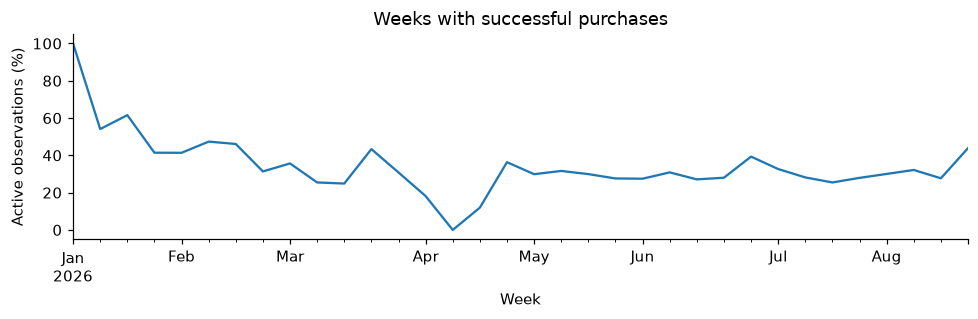

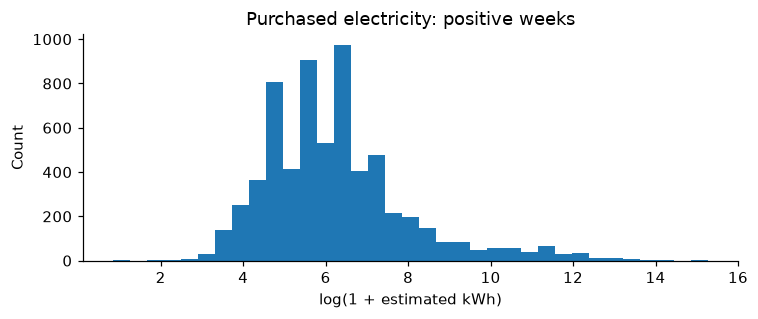

,purchase_count,purchased_kwh_est,latest_est_consumption_kwh_day
count,20198.000000,2.019800e+04,19674.000000
mean,0.421972,2.620670e+03,522.003953
std,0.750716,4.363556e+04,6849.495385
min,0.000000,0.000000e+00,0.059878
25%,0.000000,0.000000e+00,12.714954
50%,0.000000,0.000000e+00,40.555384
75%,1.000000,1.302127e+02,130.221484
max,14.000000,4.322547e+06,561569.496269


In [21]:
#Inspecting feaure quality without displaying customer indetifiers.
weekly = pd.read_csv(WORK / "prepaid_customer_week_features_v2.csv")
weekly["period_start"] = pd.to_datetime(weekly["period_start"])
active = weekly.assign(active=weekly.purchase_count.gt(0))
active.groupby("period_start").active.mean().mul(100).plot(figsize=(9,3))
finish_plot("Weeks with successful purchases", "Week", "Active observations (%)")

plt.figure(figsize=(7, 3))
plt.hist(np.log1p(weekly.loc[weekly.purchased_kwh_est.gt(0), "purchased_kwh_est"]), bins=35)
finish_plot("Purchased electricity: positive weeks", "log(1 + estimated kWh)", "Count")
display(weekly[["purchase_count", "purchased_kwh_est", "latest_est_consumption_kwh_day"]].describe())

# 3. Eligibility, chronological splitting and scaling, Version 3
I used a chronological training-validation-testing split in this way: 57.78%-13.65%-28.57%

I excluded the partial periods and unavailable history rather than filling unknown rates with zero. Then, I compared baseline/enhanced features and three scalers. I fit each scaler on training data only 

In [22]:
if RUN_PIPELINE:
    from pathlib import Path
    import pandas as pd, numpy as np, json, hashlib, joblib
    from sklearn.preprocessing import RobustScaler, StandardScaler, MinMaxScaler
    P = WORK
    base = ['purchase_count', 'purchased_kwh_est', 'days_since_last_successful_purchase']
    extra = ['historical_median_interval_days', 'latest_est_consumption_kwh_day', 'prior_median_est_consumption_kwh_day', 'relative_purchase_gap', 'consumption_rate_ratio', 'new_completed_intervals', 'days_since_latest_completed_interval', 'purchased_kwh_log_deviation', 'purchase_count_log_deviation', 'consecutive_complete_zero_purchase_periods']
    keys = ['customer_no', 'meter_no', 'period_start', 'period_end']
    report = {}
    models = {}
    # Split by period end, never by random row assignment.
    for kind in ['week', 'month']:
        src = P / f'prepaid_customer_{kind}_features_v2.csv'
        d = pd.read_csv(src, dtype={'customer_no': str, 'meter_no': str})
        assert not d.duplicated(keys).any()
        end = pd.to_datetime(d.period_end)
        cut1 = '2026-06-07' if kind == 'week' else '2026-05-31'
        cut2 = '2026-07-05' if kind == 'week' else '2026-06-30'
        d['split'] = np.where(end <= cut1, 'train', np.where(end <= cut2, 'validation', 'test'))
        report[kind] = {'source_sha256': hashlib.sha256(src.read_bytes()).hexdigest(), 'rows': len(d), 'partial': int(d.partial_first_period.sum()), 'splits': d.groupby('split').size().to_dict()}
        for name, cols in [('baseline', base), ('enhanced', base + extra)]:
            mask = d.partial_first_period.eq(0) & np.isfinite(d[cols]).all(axis=1)
            if name == 'enhanced':
                mask &= d.completed_intervals_to_date.ge(4) & d.prior_complete_periods.ge(1) & d.consumption_rate_ratio.gt(0)
            x = d.loc[mask, cols].copy()
            meta = d.loc[mask, keys + ['split']].copy()
            train = meta.split.eq('train')
            assert train.any()
            for c in cols:
                if c == 'consumption_rate_ratio':
                    x[c] = np.log(x[c])
                elif not c.endswith('_log_deviation'):
                    assert x[c].ge(0).all()
                    x[c] = np.log1p(x[c])
            assert np.isfinite(x).all().all()
            iqr = x.loc[train].quantile(0.75) - x.loc[train].quantile(0.25)
            zero = iqr[iqr == 0].index.tolist()
            r = {'counts': meta.groupby('split').size().to_dict(), 'pairs': int(meta[keys[:2]].drop_duplicates().shape[0]), 'zero_iqr': zero, 'scalers': {}, 'features': cols}
            for label, sc in [('robust', RobustScaler()), ('standard', StandardScaler()), ('minmax', MinMaxScaler())]:
                sc.fit(x.loc[train])
                z = pd.DataFrame(sc.transform(x), index=x.index, columns=cols)
                assert np.isfinite(z).all().all()
                r['scalers'][label] = {'train_max_abs': float(z.loc[train].abs().max().max()), 'test_max_abs': float(z.loc[meta.split.eq('test')].abs().max().max()), 'test_outside_0_1_pct': float(((z.loc[meta.split.eq('test')] < 0) | (z.loc[meta.split.eq('test')] > 1)).to_numpy().mean() * 100)}
                models[f'{kind}_{name}_{label}'] = sc
                pd.concat([meta, z], axis=1).to_csv(P / f'prepaid_{kind}_{name}_{label}_v3.csv', index=False)
            report[kind][name] = r
            d[f'{name}_eligible'] = mask
        d[keys + ['split', 'partial_first_period', 'baseline_eligible', 'enhanced_eligible']].to_csv(P / f'prepaid_{kind}_eligibility_v3.csv', index=False)
    joblib.dump(models, P / 'prepaid_scalers_v3.joblib')
    (P / 'prepaid_preprocessing_audit_v3.json').write_text(json.dumps(report, indent=2))
    print(json.dumps(report, indent=2))


{
  "week": {
    "source_sha256": "c84e0d96c717e9bb1d0b89767ed3acbccf89b93e2dd679cb02a479ee57b91d03",
    "rows": 20198,
    "partial": 50,
    "splits": {
      "test": 5647,
      "train": 11836,
      "validation": 2715
    },
    "baseline": {
      "counts": {
        "test": 5634,
        "train": 11805,
        "validation": 2709
      },
      "pairs": 723,
      "zero_iqr": [],
      "scalers": {
        "robust": {
          "train_max_abs": 3.9068905956085187,
          "test_max_abs": 3.0,
          "test_outside_0_1_pct": 30.58809608330375
        },
        "standard": {
          "train_max_abs": 6.2348127073424955,
          "test_max_abs": 4.637092055638268,
          "test_outside_0_1_pct": 89.30304106022956
        },
        "minmax": {
          "train_max_abs": 1.0,
          "test_max_abs": 1.0869948554342883,
          "test_outside_0_1_pct": 2.1890900485149687
        }
      },
      "features": [
        "purchase_count",
        "purchased_kwh_est",
       

# 4. Entropy dependency audit

I used Shannon and Min Entropy dependency matrices using training-only quantile bins. Min Entropy is deffered because the empircal matrix is indefinite

In [23]:
if RUN_PIPELINE:
    import pandas as pd, numpy as np, json
    from pathlib import Path
    from sklearn.metrics import mutual_info_score
    p = WORK
    x = pd.read_csv(p / 'prepaid_week_enhanced_robust_v3.csv', dtype={'customer_no': str, 'meter_no': str})
    x = x.loc[x.split == 'train'].iloc[:, 5:]
    assert x.shape == (9567, 13) and np.isfinite(x).all().all()
    b = np.column_stack([pd.qcut(x[c], 10, labels=False, duplicates='drop').to_numpy() for c in x])

    # Empirical entropy in bits.
    def H(a, kind):
        _, n = np.unique(a, axis=0, return_counts=True)
        v = n / n.sum()
        return float(-np.sum(v * np.log2(v)) if kind == 'shannon' else -np.log2(v.max()))
    out = {}
    for kind in ['shannon', 'min']:
        h = np.array([H(b[:, i], kind) for i in range(13)])
        q = np.array([[h[i] + h[j] - H(b[:, [i, j]], kind) for j in range(13)] for i in range(13)])
        eig = np.linalg.eigvalsh(q)
        pd.DataFrame(q, index=x.columns, columns=x.columns).to_csv(p / f'edufs_{kind}_dependency.csv')
        out[kind] = {'min_eigenvalue': float(eig.min()), 'max_eigenvalue': float(eig.max()), 'min_entry': float(q.min()), 'entropy': dict(zip(x.columns, h.tolist()))}
    out['rows'] = len(x)
    out['exact_duplicate'] = bool(np.array_equal(x.iloc[:, 2], x.iloc[:, 9]))
    (p / 'edufs_dependency_audit.json').write_text(json.dumps(out, indent=2))
    print(json.dumps(out, indent=2))

{
  "shannon": {
    "min_eigenvalue": -5.486601660019704e-16,
    "max_eigenvalue": 8.223282375769106,
    "min_entry": 0.010079508579232677,
    "entropy": {
      "purchase_count": 0.3990926619568282,
      "purchased_kwh_est": 1.356749937056906,
      "days_since_last_successful_purchase": 3.2845065293393576,
      "historical_median_interval_days": 3.3046798439392058,
      "latest_est_consumption_kwh_day": 3.321925879728533,
      "prior_median_est_consumption_kwh_day": 3.3219238317485744,
      "relative_purchase_gap": 3.315934050118793,
      "consumption_rate_ratio": 3.321911225481035,
      "new_completed_intervals": 0.3734111650123598,
      "days_since_latest_completed_interval": 3.2845065293393576,
      "purchased_kwh_log_deviation": 1.9241441898832852,
      "purchase_count_log_deviation": 0.9484567004272878,
      "consecutive_complete_zero_purchase_periods": 2.012247969639094
    }
  },
  "min": {
    "min_eigenvalue": -0.45338388656113765,
    "max_eigenvalue": 10.458

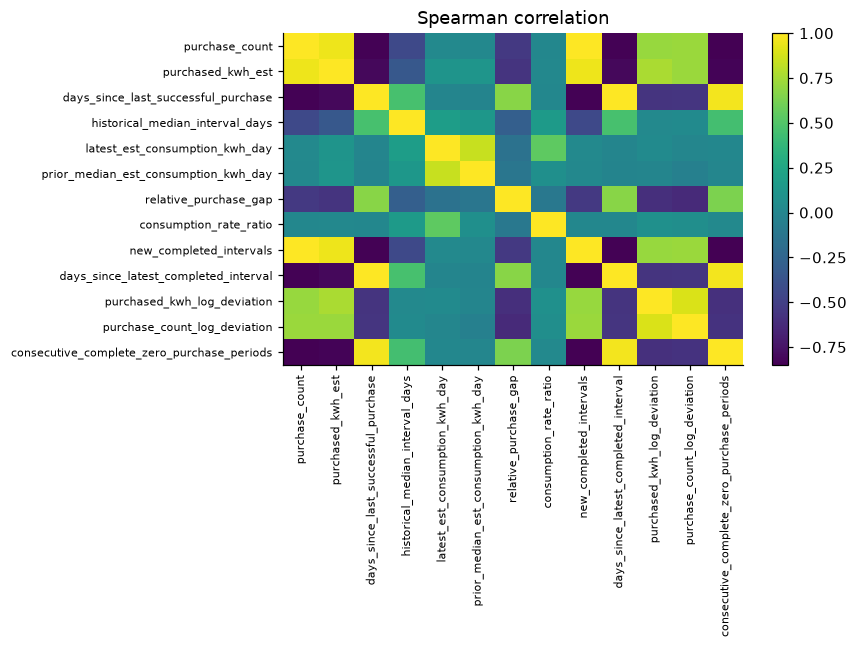

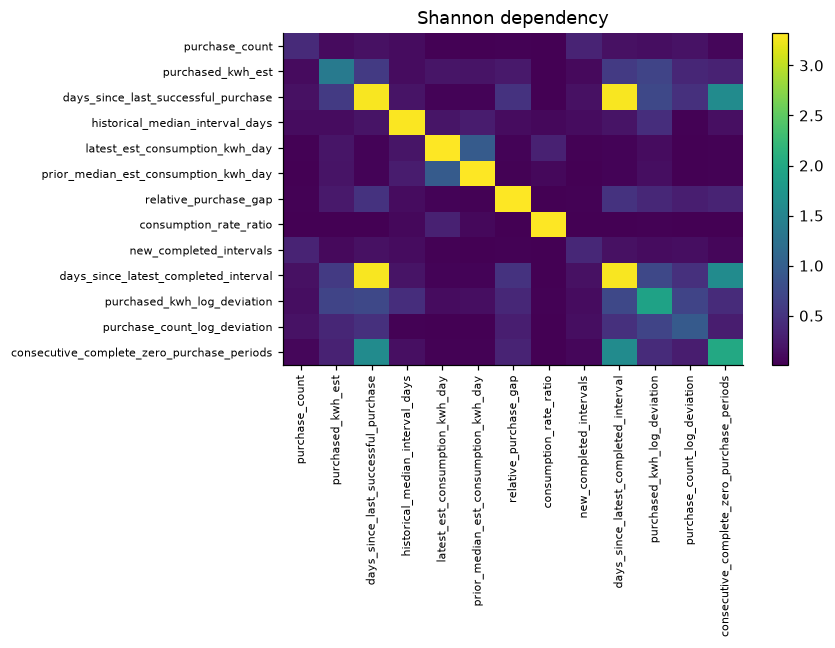

In [24]:
# Inspect correlations and entropy dependencies using training data only.
train = pd.read_csv(WORK / "prepaid_week_enhanced_robust_v3.csv")
train = train.loc[train.split.eq("train")].iloc[:, 5:]
for title, matrix in [("Spearman correlation", train.corr(method="spearman")),
                      ("Shannon dependency", pd.read_csv(WORK / "edufs_shannon_dependency.csv", index_col=0))]:
    fig, ax = plt.subplots(figsize=(8, 6))
    im = ax.imshow(matrix, aspect="auto", cmap="viridis")
    ax.set_xticks(range(len(matrix)), matrix.columns, rotation=90, fontsize=7)
    ax.set_yticks(range(len(matrix)), matrix.index, fontsize=7)
    fig.colorbar(im, ax=ax)
    finish_plot(title)

# 5. Reconstructed EDUFS optimization, Version 4 (V4)

I built a sparse 20-neighbor RBF Laplacian, alternate W/G/F/K updates, evaluated five seeds and five sensitivity settings, and exported fetaure subsets. 

This is a relaxed reconstruction, not exact dense-graph EDUFS.

In [27]:
if RUN_PIPELINE:
    import numpy as np, pandas as pd, json, hashlib, sys
    from pathlib import Path
    from scipy.sparse import csr_matrix, diags
    from sklearn.neighbors import NearestNeighbors
    from sklearn.cluster import KMeans
    from sklearn.metrics import mutual_info_score
    from scipy.linalg import svd
    from itertools import combinations
    p = WORK / 'edufs_v4'
    root = WORK
    src = root / 'prepaid_week_enhanced_robust_v3.csv'
    df = pd.read_csv(src, dtype={'customer_no': str, 'meter_no': str})
    cols = list(df.columns[5:])
    train = df[df.split == 'train']
    A = train[cols].to_numpy()
    n, d = A.shape
    assert (n, d) == (9567, 13) and np.isfinite(A).all()
    X = A.T
    XX = X @ X.T
    b = np.column_stack([pd.qcut(train[c], 10, labels=False, duplicates='drop') for c in cols])
    Q = np.array([[mutual_info_score(b[:, i], b[:, j]) / np.log(2) for j in range(d)] for i in range(d)])
    assert np.linalg.eigvalsh(Q).min() > -1e-09
    pd.DataFrame(Q, index=cols, columns=cols).to_csv(p / 'dependency.csv')

    # Symmetric sparse RBF graph; avoid dense pairwise storage.
    def graph(k):
        dist, idx = NearestNeighbors(n_neighbors=k + 1).fit(A).kneighbors(A)
        mask = idx != np.arange(n)[:, None]
        rr = np.broadcast_to(np.arange(n)[:, None], idx.shape)[mask]
        cc = idx[mask]
        dd = dist[mask]
        sigma = np.median(dd[dd > 0])
        S = csr_matrix((np.exp(-(dd / sigma) ** 2), (rr, cc)), shape=(n, n))
        S = S.maximum(S.T)
        deg = np.asarray(S.sum(1)).ravel()
        L = diags(deg) - S
        assert np.max(abs(L @ np.ones(n))) < 1e-10
        return (L, deg, dict(k=k, sigma=float(sigma), edges=int(S.nnz // 2), max_degree=float(deg.max())))

    def polar(B):
        u, s, v = svd(B, full_matrices=False, check_finite=False)
        return u @ v

    # Alternating minimization of the relaxed objective.
    def fit(L, deg, c, seed, alpha, beta, delta, gamma=1.0, maxiter=1500, tol=1e-07):
        lab = KMeans(n_clusters=c, n_init=1, random_state=seed).fit_predict(A)
        F = np.eye(c)[lab]
        F /= np.linalg.norm(F, axis=0)
        K = F.copy()
        G = np.eye(c)
        W = np.zeros((d, c))
        eps = 1e-08

        def obj():
            return float(np.sum((X.T @ W - F @ G.T) ** 2) + alpha * np.sqrt(np.sum(W * W, 1) + eps ** 2).sum() + beta * np.sum(W * (Q @ W)) + gamma * np.sum((K - F) ** 2) + delta * np.sum(F * (L @ F)))
        hist = [obj()]
        stable = 0
        h = gamma + 2 * delta * deg.max() + 1e-09
        for it in range(maxiter):
            G = polar(W.T @ X @ F) if it else G
            D = 1 / (2 * np.sqrt(np.sum(W * W, 1) + eps ** 2)) if it else np.ones(d)
            W = np.linalg.solve(XX + alpha * np.diag(D) + beta * Q, X @ F @ G.T)
            B = X.T @ W @ G + gamma * K
            F = polar(B + h * F - gamma * F - delta * (L @ F))
            K = np.maximum(F, 0)
            val = obj()
            hist.append(val)
            if it > 0 and val > hist[-2] + 1e-09:
                raise RuntimeError('objective increase')
            stable = stable + 1 if abs(val - hist[-2]) / max(1, abs(hist[-2])) < tol else 0
            if stable >= 10:
                break
        score = np.linalg.norm(W, axis=1)
        order = np.argsort(-score, kind='stable')
        return (score, order, dict(c=c, seed=seed, alpha=alpha, beta=beta, delta=delta, gamma=gamma, iterations=it + 1, converged=stable >= 10, objective_start=hist[0], objective_end=hist[-1], orthogonality=float(np.linalg.norm(F.T @ F - np.eye(c))), negative_mass=float(np.linalg.norm(F - K)), history=hist))
    L, deg, g = graph(20)
    runs = []
    scores = []
    orders = []
    for c, seed, a, beta, delta in [(3, s, 0.01, 0.1, 0.01) for s in [11, 22, 33, 44, 55]] + [(2, 11, 0.01, 0.1, 0.01), (4, 11, 0.01, 0.1, 0.01), (3, 11, 0.1, 0.1, 0.01), (3, 11, 0.01, 1, 0.01), (3, 11, 0.01, 0.1, 0.1)]:
        s, o, r = fit(L, deg, c, seed, a, beta, delta)
        runs.append(r)
        scores.append(s)
        orders.append(o)
        print(c, seed, a, beta, delta, r['iterations'], r['converged'], r['objective_end'], flush=True)
    rank = np.argsort(np.argsort(-np.array(scores), axis=1), axis=1) + 1
    primary = rank[:5]
    consensus = np.argsort(primary.mean(0), kind='stable')
    tab = pd.DataFrame({'feature': cols, 'mean_rank_primary': primary.mean(0), 'mean_rank_all': rank.mean(0), 'mean_score_primary': np.mean(scores[:5], axis=0), 'consensus_rank': np.argsort(consensus) + 1})
    tab.sort_values('consensus_rank').to_csv(p / 'rankings.csv', index=False)
    for k in [4, 6, 8, 10, 13]:
        chosen = [cols[i] for i in consensus[:k]] if k != 13 else cols
        df[list(df.columns[:5]) + chosen].to_csv(p / f'weekly_{k}_features.csv', index=False)
    dup = 'days_since_latest_completed_interval'
    df.drop(columns=dup).to_csv(p / 'weekly_12_duplicate_control.csv', index=False)
    stability = {str(k): float(np.mean([len(set(a[:k]) & set(b[:k])) / len(set(a[:k]) | set(b[:k])) for a, b in combinations(orders[:5], 2)])) for k in [4, 6, 8, 10]}
    (p / 'audit.json').write_text(json.dumps(dict(source_sha256=hashlib.sha256(src.read_bytes()).hexdigest(), graph=g, train_rows=n, split_counts=df.split.value_counts().to_dict(), q_min_eigenvalue=float(np.linalg.eigvalsh(Q).min()), runs=runs, stability=stability, rankings=tab.sort_values('consensus_rank').to_dict('records')), indent=2))
    print(tab.sort_values('consensus_rank').to_string(index=False))
    print(stability)

3 11 0.01 0.1 0.01 386 True 0.018474770082214063
3 22 0.01 0.1 0.01 386 True 0.01847477008221408
3 33 0.01 0.1 0.01 386 True 0.018474770082214098
3 44 0.01 0.1 0.01 386 True 0.018474770082214046
3 55 0.01 0.1 0.01 309 True 0.01838781227444939
2 11 0.01 0.1 0.01 1500 False 0.005100944028644461
4 11 0.01 0.1 0.01 996 True 0.0444535490517091
3 11 0.1 0.1 0.01 454 True 0.0280130625262615
3 11 0.01 1 0.01 433 True 0.022095734442698196
3 11 0.01 0.1 0.1 941 True 0.0379458502071089
                                   feature  mean_rank_primary  mean_rank_all  mean_score_primary  consensus_rank
           historical_median_interval_days                1.8            2.6        2.047102e-02               1
                            purchase_count                2.2            3.9        2.484946e-02               2
consecutive_complete_zero_purchase_periods                2.8            2.5        1.974059e-02               3
                         purchased_kwh_est                4.6       

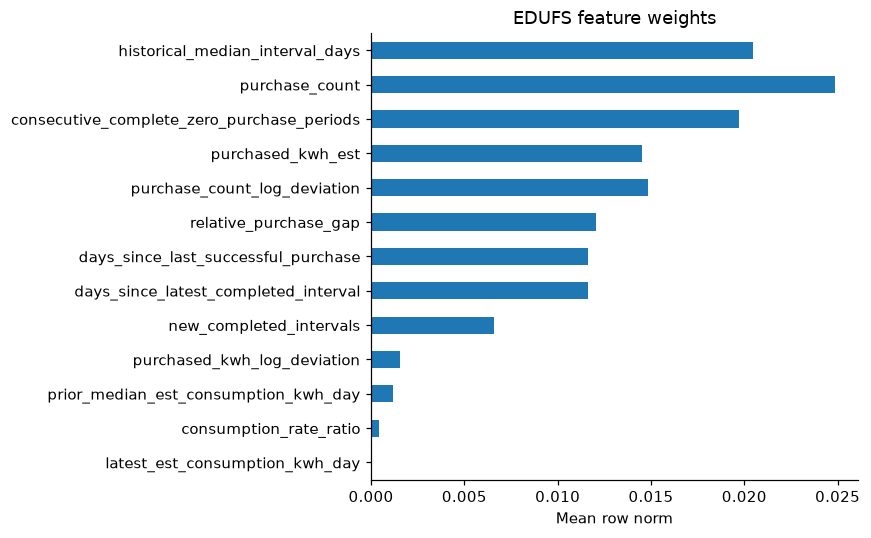

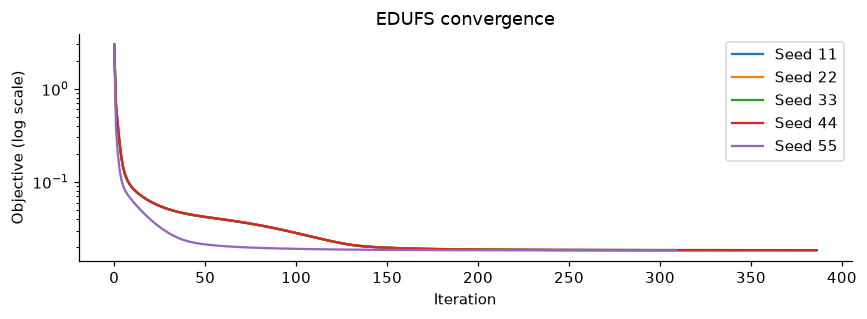

In [28]:
import json
rankings = pd.read_csv(WORK / "edufs_v4/rankings.csv").sort_values("consensus_rank")
rankings.set_index("feature").mean_score_primary.iloc[::-1].plot.barh(figsize=(8, 5))
finish_plot("EDUFS feature weights", "Mean row norm")

edufs_audit = json.loads((WORK / "edufs_v4/audit.json").read_text())
plt.figure(figsize=(8, 3))
for run in edufs_audit["runs"][:5]:
    plt.semilogy(run["history"], label=f"Seed {run['seed']}")
plt.legend()
finish_plot("EDUFS convergence", "Iteration", "Objective (log scale)")

# 6. K-Mediods clustering, Version 5 (V5)

I compare seven feature configurations (including E5), K=2-6 and three seeds.
Sampled PAM optimizes on 350 training rows.

In [29]:
if RUN_PIPELINE:
    import numpy as np, pandas as pd, json, time, hashlib
    from pathlib import Path
    from scipy.spatial.distance import cdist
    from sklearn.metrics import silhouette_score, davies_bouldin_score, calinski_harabasz_score, adjusted_rand_score
    from itertools import combinations
    from threadpoolctl import threadpool_limits
    P = WORK / 'edufs_v4'
    O = WORK / 'kmedoids_v5'
    base = pd.read_csv(P / 'weekly_13_features.csv', dtype=str)
    keys = list(base.columns[:5])
    cols = list(base.columns[5:])
    tr = base.split == 'train'
    va = base.split == 'validation'
    common = base.loc[va, cols].astype(float).to_numpy()
    assert base[keys].duplicated().sum() == 0
    sets = {str(n): P / f'weekly_{n}_features.csv' for n in [13, 10, 8, 6, 4]}
    sets['12'] = P / 'weekly_12_duplicate_control.csv'

    # Sampled PAM: initialize medoids and search improving swaps.
    def pam(x, k, seed):
        rng = np.random.default_rng(seed)
        ix = rng.choice(len(x), 350, replace=False)
        D = cdist(x[ix], x[ix])
        m = [int(rng.integers(len(ix)))]
        for _ in range(k - 1):
            w = D[:, m].min(1) ** 2
            m.append(int(rng.choice(len(ix), p=w / w.sum())))
        for it in range(100):
            ds = D[:, m]
            lab = ds.argmin(1)
            near = ds.min(1)
            second = np.partition(ds, 1, axis=1)[:, 1]
            best = 0
            move = None
            for j in range(k):
                rest = np.where(lab == j, second, near)
                gain = (np.minimum(rest[:, None], D) - near[:, None]).sum(0)
                gain[m] = np.inf
                h = gain.argmin()
                if gain[h] < best - 1e-09:
                    best = gain[h]
                    move = (j, h)
            if move is None:
                break
            m[move[0]] = move[1]
        return (ix[m], it + 1, move is None)
    rows = []
    models = []
    assignments = []
    profiles = []
    with threadpool_limits(limits=1):
        for name in ['13', '12', '10', '8', '6', '4', 'E5']:
            if name == 'E5':
                fs = list(pd.read_csv(sets['6'], nrows=0).columns[5:]) + ['latest_est_consumption_kwh_day', 'consumption_rate_ratio']
                df = base[keys + fs]
            else:
                df = pd.read_csv(sets[name], dtype=str)
                fs = list(df.columns[5:])
                assert df[keys].equals(base[keys])
                assert np.allclose(df[fs].astype(float), base[fs].astype(float))
            x = df.loc[tr, fs].astype(float).to_numpy()
            v = df.loc[va, fs].astype(float).to_numpy()
            assert np.isfinite(x).all() and np.isfinite(v).all()
            for k in range(2, 7):
                group = []
                labs = []
                for seed in [11, 22, 33]:
                    start = time.perf_counter()
                    m, it, conv = pam(x, k, seed)
                    dt = cdist(x, x[m])
                    dv = cdist(v, x[m])
                    l = dv.argmin(1)
                    labs.append(l)
                    counts = np.bincount(l, minlength=k)
                    valid = len(np.unique(l)) == k
                    r = dict(subset=name, features=len(fs), k=k, seed=seed, train_mean_distance=float(dt.min(1).mean()), val_mean_distance=float(dv.min(1).mean()), silhouette=float(silhouette_score(v, l, sample_size=1000, random_state=42)) if valid else np.nan, common_silhouette=float(silhouette_score(common, l, sample_size=1000, random_state=42)) if valid else np.nan, db=float(davies_bouldin_score(v, l)) if valid else np.nan, ch=float(calinski_harabasz_score(v, l)) if valid else np.nan, min_val_cluster=int(counts.min()), iterations=it, converged=conv, seconds=time.perf_counter() - start)
                    rows.append(r)
                    group.append((r, m, l))
                stability = np.mean([adjusted_rand_score(a, b) for a, b in combinations(labs, 2)])
                for r, m, l in group:
                    r['stability_ari'] = stability
                r, m, l = min(group, key=lambda a: a[0]['train_mean_distance'])
                models.append({**r, 'columns': fs, 'medoids': x[m].tolist()})
                a = base.loc[va, keys].copy()
                a['subset'] = name
                a['k'] = k
                a['cluster'] = l
                a['distance'] = cdist(v, x[m]).min(1)
                assignments.append(a)
            print(name, 'done', flush=True)
    pd.DataFrame(rows).to_csv(O / 'runs.csv', index=False)
    pd.DataFrame([{k: v for k, v in r.items() if k not in ['columns', 'medoids']} for r in models]).to_csv(O / 'models.csv', index=False)
    (O / 'medoids.json').write_text(json.dumps(models))
    pd.concat(assignments).to_csv(O / 'validation_assignments.csv', index=False)

13 done
12 done
10 done
8 done
6 done
4 done
E5 done


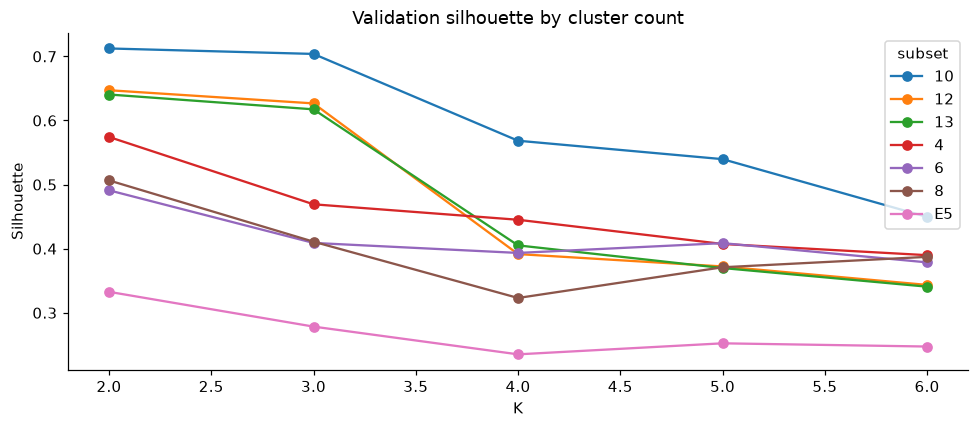

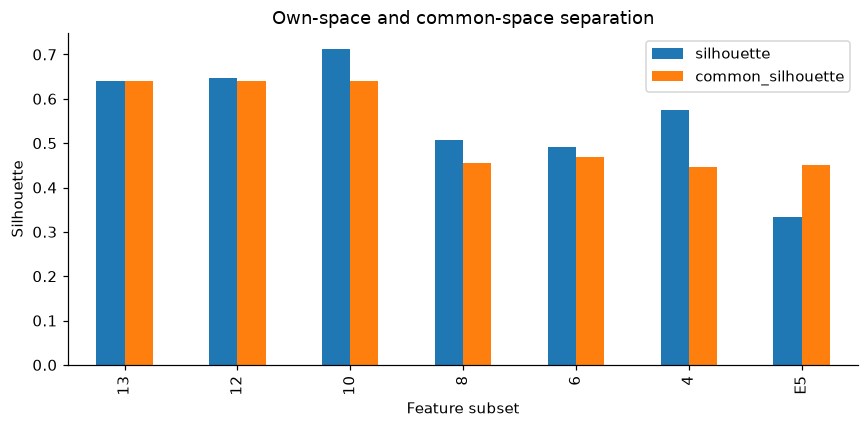

In [30]:
clusters = pd.read_csv(WORK / "kmedoids_v5/models.csv", dtype={"subset": str})
clusters.pivot(index="k", columns="subset", values="silhouette").plot(marker="o", figsize=(9, 4))
finish_plot("Validation silhouette by cluster count", "K", "Silhouette")
clusters.query("k == 2").set_index("subset")[["silhouette", "common_silhouette"]].plot.bar(figsize=(8, 4))
finish_plot("Own-space and common-space separation", "Feature subset", "Silhouette")

# 7. Unsupervised anomaly detection, Version 6 (V6)
I trained isolation Forrest, novelty-mode LOF and One-Class SVM globally wna within K=2 clusters.

Training-relative percentiles are exploratory. Part 8 replaces them with separate calibration references

In [31]:
if RUN_PIPELINE:
    import os
    os.environ['OPENBLAS_NUM_THREADS'] = '1'
    os.environ['OMP_NUM_THREADS'] = '1'
    import numpy as np, pandas as pd, json, time, pathlib, joblib
    from scipy.spatial.distance import cdist
    from scipy.stats import rankdata, spearmanr
    from sklearn.ensemble import IsolationForest
    from sklearn.neighbors import LocalOutlierFactor
    from sklearn.svm import OneClassSVM
    from itertools import combinations
    P = WORK / 'anomaly_v6'
    R = WORK
    keys = ['customer_no', 'meter_no', 'period_start', 'period_end', 'split']
    d = pd.read_csv(R / 'edufs_v4/weekly_13_features.csv', dtype=str)
    cols = [c for c in d if c not in keys]
    d[cols] = d[cols].astype(float)
    t = d[d.split == 'train']
    v = d[d.split == 'validation']
    assert len(t) == 9567 and len(v) == 2261
    models = json.load(open(R / 'kmedoids_v5/medoids.json'))
    print('subsets', [(m['subset'], m['k']) for m in models if m['k'] == 2], flush=True)
    rows = []
    scores = []
    agreements = []
    fitted = {}
    # Use frozen training medoids and score unseen validation rows.
    for m in models:
        if m['k'] != 2:
            continue
        name = m['subset']
        c = m['columns']
        X = t[c].to_numpy()
        Y = v[c].to_numpy()
        med = np.array(m['medoids'])
        a = cdist(X, med).argmin(1)
        b = cdist(Y, med).argmin(1)
        for mode in ['global', 'cluster']:
            results = {}
            for alg in ['IF', 'LOF', 'OCSVM']:
                start = time.perf_counter()
                reps = []
                for seed in [11, 22, 33] if alg == 'IF' else [11]:
                    s = np.empty(len(Y))
                    raw = np.empty(len(Y))
                    groupmodels = []
                    for g in [-1] if mode == 'global' else range(len(med)):
                        ix = np.ones(len(X), bool) if g == -1 else a == g
                        jx = np.ones(len(Y), bool) if g == -1 else b == g
                        A = X[ix]
                        B = Y[jx]
                        assert len(A) > 20
                        model = IsolationForest(n_estimators=100, max_samples=256, random_state=seed, n_jobs=1) if alg == 'IF' else LocalOutlierFactor(n_neighbors=20, novelty=True, n_jobs=1) if alg == 'LOF' else OneClassSVM(nu=0.05, gamma='scale', kernel='rbf')
                        model.fit(A)
                        z = -model.score_samples(B)
                        ref = np.sort(-model.score_samples(A))
                        raw[jx] = z
                        s[jx] = np.searchsorted(ref, z, side='right') / len(ref)
                        groupmodels.append((g, model, ref))
                    reps.append(s)
                    fitted[name, mode, alg, seed] = groupmodels
                s = np.mean(reps, axis=0)
                flag = s >= 0.95
                top = np.argsort(-s, kind='stable')[:int(np.ceil(0.05 * len(s)))]
                topmask = np.zeros(len(s), bool)
                topmask[top] = True
                stab = [len(set(np.argsort(-x, kind='stable')[:len(top)]) & set(np.argsort(-y, kind='stable')[:len(top)])) / len(set(np.argsort(-x, kind='stable')[:len(top)]) | set(np.argsort(-y, kind='stable')[:len(top)])) for x, y in combinations(reps, 2)]
                rows.append(dict(subset=name, mode=mode, algorithm=alg, features=len(c), fits=len(reps) * len(groupmodels), flags=int(flag.sum()), flag_rate=flag.mean(), top_n=len(top), boundary_ties=int((s == s[top[-1]]).sum()), seed_jaccard=np.mean(stab) if stab else None, seconds=time.perf_counter() - start, train_cluster_sizes=str(np.bincount(a).tolist())))
                results[alg] = topmask
                z = v[keys].copy()
                z['subset'] = name
                z['mode'] = mode
                z['algorithm'] = alg
                z['cluster'] = b
                z['percentile_score'] = s
                z['threshold_flag'] = flag
                z['top_budget_flag'] = topmask
                scores.append(z)
            for x, y in combinations(results, 2):
                A = results[x]
                B = results[y]
                agreements.append(dict(subset=name, mode=mode, pair=x + '-' + y, jaccard=(A & B).sum() / (A | B).sum()))
        print('finished', name, flush=True)
    pd.DataFrame(rows).to_csv(P / 'summary.csv', index=False)
    pd.concat(scores).to_csv(P / 'validation_scores.csv', index=False)
    pd.DataFrame(agreements).to_csv(P / 'agreement.csv', index=False)
    joblib.dump(fitted, P / 'models.joblib', compress=3)

subsets [('13', 2), ('12', 2), ('10', 2), ('8', 2), ('6', 2), ('4', 2), ('E5', 2)]
finished 13
finished 12
finished 10
finished 8
finished 6
finished 4
finished E5


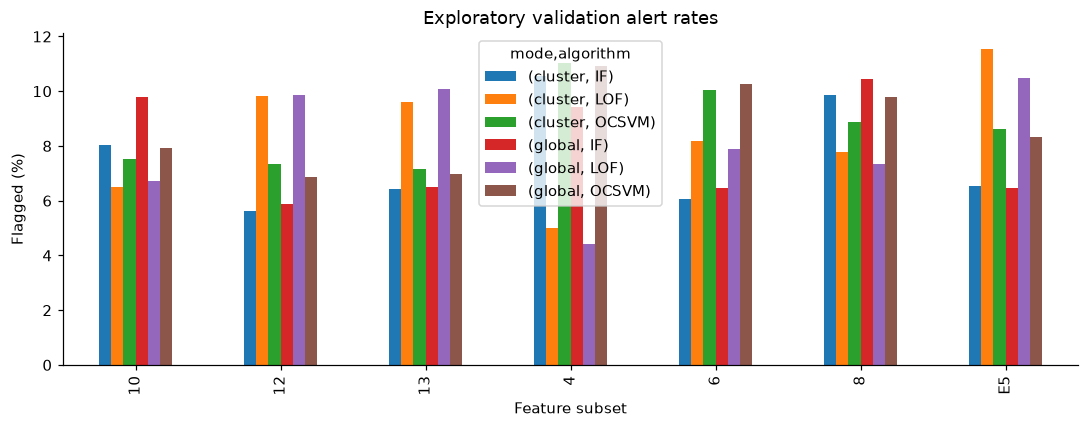

In [33]:
alerts = pd.read_csv(WORK / "anomaly_v6/summary.csv", dtype={"subset": str})
alerts.pivot_table(index="subset", columns=["mode", "algorithm"], values="flag_rate").mul(100).plot.bar(figsize=(10, 4))
finish_plot("Exploratory validation alert rates", "Feature subset", "Flagged (%)")

# 8. Evaluation (V7)

Calibration on earlier validation weeks and using later validation weeks and evaluating the frozen models on testing.

Monthly models are refitted with transferred weekly feature definitions. Original background rows are not verified normal labels

In [32]:
if RUN_PIPELINE:
    import os
    os.environ['OPENBLAS_NUM_THREADS'] = '1'
    os.environ['OMP_NUM_THREADS'] = '1'
    import numpy as np, pandas as pd, json, joblib, math, statistics, pathlib
    from datetime import date, timedelta
    from collections import defaultdict
    from scipy.spatial.distance import cdist
    from sklearn.preprocessing import RobustScaler
    from sklearn.metrics import average_precision_score, roc_auc_score, precision_recall_fscore_support
    from sklearn.ensemble import IsolationForest
    from sklearn.neighbors import LocalOutlierFactor
    from sklearn.svm import OneClassSVM
    P = WORK / 'evaluation_v7'
    R = WORK
    SRC = SOURCE
    D = defaultdict(lambda: defaultdict(lambda: [0, 0.0]))
    for r in records():
        if r['Excute Status'] != 'Execution Successful':
            continue
        m = RATE_RE.findall(r['Tariff Program'])
        a = number(r['Resource Amount(UGX)'])
        k = (r['Customer No.'].strip(), r['Meter No.'].strip())
        if len(m) != 1 or a is None or a < 0 or (float(m[0]) <= 0):
            continue
        d = date.fromisoformat(r['Vending Date'][:10])
        D[k][d][0] += 1
        D[k][d][1] += a / float(m[0])
    keys = ['customer_no', 'meter_no', 'period_start', 'period_end', 'split']
    models = [m for m in json.load(open(R / 'kmedoids_v5/medoids.json')) if m['k'] == 2]
    fitted = joblib.load(R / 'anomaly_v6/models.joblib')
    cols = models[0]['columns']
    rng = np.random.default_rng(20261126)

    def trans(d):
        x = d[cols].copy()
        for c in cols:
            if c == 'consumption_rate_ratio':
                x[c] = np.log(x[c])
            elif not c.endswith('_log_deviation'):
                x[c] = np.log1p(x[c])
        return x

    # Recompute all affected features as of the observation end.
    def features(days, s, e, kind):
        ds = sorted((d for d in days if d <= e))
        first = ds[0]
        pairs = list(zip(ds, ds[1:]))
        gaps = [(b - a).days for a, b in pairs]
        rates = [days[a][1] / (b - a).days for a, b in pairs]
        if len(rates) < 4 or statistics.median(rates[:-1]) <= 0 or rates[-1] <= 0:
            return None
        n = sum((days[d][0] for d in ds if d >= s))
        q = sum((days[d][1] for d in ds if d >= s))
        age = (e - ds[-1]).days
        hq = []
        hn = []
        streak = 0

        def prev(s):
            e = s - timedelta(days=1)
            return (s - timedelta(days=7) if kind == 'week' else e.replace(day=1), e)
        ps, pe = prev(s)
        while ps >= first:
            hq.append(sum((days[d][1] for d in ds if ps <= d <= pe)))
            hn.append(sum((days[d][0] for d in ds if ps <= d <= pe)))
            ps, pe = prev(ps)
        if not hq:
            return None
        ps, pe = (s, e)
        while ps >= first and (not any((ps <= d <= pe for d in ds))):
            streak += 1
            ps, pe = prev(ps)
        return dict(purchase_count=n, purchased_kwh_est=q, days_since_last_successful_purchase=age, historical_median_interval_days=statistics.median(gaps), latest_est_consumption_kwh_day=rates[-1], prior_median_est_consumption_kwh_day=statistics.median(rates[:-1]), relative_purchase_gap=age / statistics.median(gaps), consumption_rate_ratio=rates[-1] / statistics.median(rates[:-1]), new_completed_intervals=sum((b >= s for a, b in pairs)), days_since_latest_completed_interval=age, purchased_kwh_log_deviation=math.log1p(q) - math.log1p(statistics.median(hq)), purchase_count_log_deviation=math.log1p(n) - math.log1p(statistics.median(hn)), consecutive_complete_zero_purchase_periods=streak)

    # Inject at most one scenario per customer-meter pair.
    def benchmark(raw, kind, seed):
        rng = np.random.default_rng(seed)
        scenarios = ['high_amount', 'low_amount', 'high_rate', 'low_rate', 'extra_purchase', 'inactivity', 'combined']
        result = []
        used = set()
        for scenario in scenarios:
            count = 0
            for i in rng.permutation(len(raw)):
                r = raw.iloc[i]
                k = (r.customer_no, r.meter_no)
                s = date.fromisoformat(r.period_start)
                e = date.fromisoformat(r.period_end)
                if k in used:
                    continue
                days = {d: v.copy() for d, v in D[k].items() if d <= e}
                active = sorted((d for d in days if d >= s))
                if not active:
                    continue
                orig = features(days, s, e, kind)
                if orig is None or not np.allclose([orig[c] for c in cols], r[cols].astype(float), rtol=1e-07, atol=1e-07):
                    continue
                if scenario in ['high_amount', 'low_amount', 'combined']:
                    for d in active:
                        days[d][1] *= 10 if scenario != 'low_amount' else 0.1
                if scenario in ['high_rate', 'low_rate']:
                    if len(active) < 2:
                        continue
                    days[active[-2]][1] *= 5 if scenario == 'high_rate' else 0.2
                if scenario in ['extra_purchase', 'combined']:
                    free = [s + timedelta(days=j) for j in range((e - s).days + 1) if s + timedelta(days=j) not in days]
                    if not free:
                        continue
                    d = free[int(rng.integers(len(free)))]
                    days[d] = [3, orig['purchased_kwh_est'] * (2 if scenario == 'combined' else 1)]
                if scenario == 'inactivity':
                    for d in active:
                        del days[d]
                f = features(days, s, e, kind)
                if f is None:
                    continue
                result.append({**{c: r[c] for c in keys}, **f, 'scenario': scenario})
                used.add(k)
                count += 1
                if count >= 35:
                    break
        return pd.DataFrame(result)

    def fit_alg(A, alg, seed=11, variant=0):
        if alg == 'IF':
            m = IsolationForest(n_estimators=100, max_samples=[256, 128, 512][variant], random_state=seed, n_jobs=1)
        elif alg == 'LOF':
            m = LocalOutlierFactor(n_neighbors=[20, 10, 40][variant], novelty=True, n_jobs=1)
        else:
            m = OneClassSVM(nu=[0.05, 0.02, 0.1][variant], gamma='scale')
        return m.fit(A)

    def score(ms, X):
        return np.mean([-m.score_samples(X) for m in ms], axis=0)

    # Background negatives are assumed, not independently verified.
    def evalmetrics(a, b, af, bf):
        y = np.r_[np.zeros(len(a)), np.ones(len(b))]
        z = np.r_[a, b]
        pred = np.r_[af, bf]
        p, r, f, _ = precision_recall_fscore_support(y, pred, average='binary', zero_division=0)
        return dict(ap=average_precision_score(y, z), auc=roc_auc_score(y, z), precision=p, recall=r, f1=f, background_flag_rate=np.mean(af), synthetic_n=len(b), background_n=len(a))
    rows = []
    scenarios = []
    counts = []
    frozen = []
    for kind in ['week', 'month']:
        d = pd.read_csv(R / f'prepaid_{kind}_enhanced_robust_v3.csv', dtype={c: str for c in keys})
        raw = pd.read_csv(R / f'prepaid_customer_{kind}_features_v2.csv', dtype={c: str for c in keys[:-1]})
        raw = d[keys].merge(raw, on=keys[:-1], validate='one_to_one')
        tr = d.split.eq('train')
        sc = RobustScaler().fit(trans(raw.loc[tr]))
        assert np.allclose(sc.transform(trans(raw)), d[cols], atol=1e-07)
        if kind == 'week':
            cal = d.split.eq('validation') & d.period_end.le('2026-06-21')
            sel = d.split.eq('validation') & ~cal
            test = d.split.eq('test')
        else:
            cal = d.split.eq('validation')
            sel = None
            test = d.split.eq('test')
        partitions = {'test': test}
        if sel is not None:
            partitions = {'selection': sel, **partitions}
        syn = {}
        for label, mask in partitions.items():
            b = benchmark(raw.loc[mask].reset_index(drop=True), kind, 101 if label == 'selection' else 202)
            syn[label] = (b, pd.DataFrame(sc.transform(trans(b)), columns=cols))
            counts.append(dict(kind=kind, partition=label, background=int(mask.sum()), calibration=int(cal.sum()), **b.scenario.value_counts().to_dict()))
        print(kind, counts[-1], flush=True)
        for m in models:
            name = m['subset']
            fs = m['columns']
            X = d.loc[tr, fs].to_numpy()
            C = d.loc[cal, fs].to_numpy()
            if kind == 'week':
                med = np.array(m['medoids'])
            else:
                ix = np.random.default_rng(11).choice(len(X), 350, replace=False)
                A = X[ix]
                dist = cdist(A, A)
                ids = [int(dist.sum(0).argmin()), 0]
                ids[1] = int(np.minimum(dist[:, ids[0], None], dist).sum(0).argmin())
                for _ in range(100):
                    old = ids.copy()
                    for j in [0, 1]:
                        ids[j] = int(np.minimum(dist[:, ids[1 - j], None], dist).sum(0).argmin())
                    if ids == old:
                        break
                med = A[ids]
            a = cdist(X, med).argmin(1)
            c = cdist(C, med).argmin(1)
            for mode in ['global', 'cluster']:
                for alg in ['IF', 'LOF', 'OCSVM']:
                    groups = [-1] if mode == 'global' else [0, 1]
                    fitted_groups = []
                    for g in groups:
                        ai = np.ones(len(X), bool) if g == -1 else a == g
                        ci = np.ones(len(C), bool) if g == -1 else c == g
                        if ai.sum() < 41 or ci.sum() < 10:
                            break
                        seeds = [11, 22, 33] if alg == 'IF' else [11]
                        ms = [next((z[1] for z in fitted[name, mode, alg, seed] if z[0] == g)) if kind == 'week' else fit_alg(X[ai], alg, seed) for seed in seeds]
                        refs = [np.sort(-z.score_samples(C[ci])) for z in ms]
                        fitted_groups.append((g, ms, refs))
                    if len(fitted_groups) != len(groups):
                        continue

                    def predict(Y):
                        labels = cdist(Y, med).argmin(1)
                        out = np.empty(len(Y))
                        flags = np.zeros(len(Y), bool)
                        for g, ms, refs in fitted_groups:
                            j = np.ones(len(Y), bool) if g == -1 else labels == g
                            if not j.any():
                                continue
                            ss = []
                            for z, ref in zip(ms, refs):
                                v = -z.score_samples(Y[j])
                                p = np.searchsorted(ref, v, side='right') / len(ref)
                                scale = max(np.std(ref), 1e-12)
                                p += np.maximum(v - ref[-1], 0) / scale / len(ref)
                                ss.append(p)
                            out[j] = np.mean(ss, axis=0)
                        return (out, out >= 0.95)
                    for label, mask in partitions.items():
                        b, Z = syn[label]
                        u, uf = predict(d.loc[mask, fs].to_numpy())
                        v, vf = predict(Z[fs].to_numpy())
                        r = dict(kind=kind, partition=label, subset=name, mode=mode, algorithm=alg, **evalmetrics(u, v, uf, vf))
                        rows.append(r)
                        for typ in b.scenario.unique():
                            j = b.scenario.eq(typ).to_numpy()
                            scenarios.append(dict(kind=kind, partition=label, subset=name, mode=mode, algorithm=alg, scenario=typ, n=int(j.sum()), recall=float(vf[j].mean())))
            print(kind, name, 'done', flush=True)
        pd.DataFrame(rows).to_csv(P / 'metrics.csv', index=False)
        pd.DataFrame(scenarios).to_csv(P / 'scenario_recall.csv', index=False)
        pd.DataFrame(counts).to_csv(P / 'benchmark_counts.csv', index=False)
    print('DONE', flush=True)

week {'kind': 'week', 'partition': 'test', 'background': 4731, 'calibration': 1122, 'high_amount': 35, 'low_amount': 35, 'high_rate': 35, 'low_rate': 35, 'extra_purchase': 35, 'inactivity': 35, 'combined': 35}
week 13 done
week 12 done
week 10 done
week 8 done
week 6 done
week 4 done
week E5 done
month {'kind': 'month', 'partition': 'test', 'background': 1196, 'calibration': 570, 'high_amount': 35, 'low_amount': 35, 'high_rate': 35, 'low_rate': 35, 'extra_purchase': 35, 'inactivity': 35, 'combined': 35}
month 13 done
month 12 done
month 10 done
month 8 done
month 6 done
month 4 done
month E5 done
DONE
